Picked 5 UMD Professors using Planet Terp api to ingest all of their reviews.

In [ ]:
!pip install evaluate
import pandas as pd
import requests
import numpy as np
import evaluate
import torch

professors = [
    "Justin Wyss-Gallifent",
    "Clyde Kruskal",
    "Aravind Srinivasan",
    "Nelson Padua-Perez",
    "Aubrey Zinn"
]

all_reviews = []

def get_prof(name):
  url = "https://planetterp.com/api/v1/professor"
  params = {
      "name": name,
      "reviews": "true"
  }
  response = requests.get(url, params=params)
  response.raise_for_status()
  prof_data = response.json()
  return prof_data


for prof in professors:
  data = get_prof(prof)
  reviews = data.get("reviews", [])
  for r in reviews:
    all_reviews.append({"professor": r.get("professor"),
                        "text": r.get("review"),
                        "rating": r.get("rating")
                        })
  #print(f"Professor {prof}: {data}")
print("Total reviews collected: ", len(all_reviews))
print(all_reviews)



Total reviews collected:  690
[{'professor': 'Justin Wyss-Gallifent', 'text': "Best Math professor I've ever had at UMD, hands down. If this guy is available for any Math course that you are taking, ENROLL FOR JUSTIN'S CLASS. You will definitely not regret it. He teaches in such a clear and precise manner, and he is also a very nice guy that is willing to help you after class. He genuinely loves to teach to students, and it really shows. ", 'rating': 5}, {'professor': 'Justin Wyss-Gallifent', 'text': 'He is a great teacher I highly recommend him, but you can obviously tell that by his rating. ', 'rating': 5}, {'professor': 'Justin Wyss-Gallifent', 'text': "Justin is one of the best, if not the best professor I have had at UMD. He always comes in prepared, and since he has been teaching this class for years, he knows and stresses all the places where people tend to make mistakes, so you won't make them. He has a step-by-step approach to solving every problem you will run into. In additi

In [ ]:
df_reviews = pd.DataFrame(all_reviews)
df = df_reviews.dropna()
df = df[df["text"].str.strip() != ""]   # Remove empty reviews
df = df.drop(columns=["professor"]) # Avoiding professor bias
df["label"] = df["rating"] - 1
df.head(700)



,text,rating,label
0,"Best Math professor I've ever had at UMD, hand...",5,4
1,"He is a great teacher I highly recommend him, ...",5,4
2,"Justin is one of the best, if not the best pro...",5,4
3,"Didn't think he would live up to the hype, but...",5,4
4,Justin is awesome! I had the pleasure of him b...,5,4
...,...,...,...
685,she's is amazing so and helpful. she truly wan...,5,4
686,TAKE ENGLISH101 WITH ZINN. THE BEST ENGLISH TE...,5,4
687,"I'd say if you need to take 393, then Zinn is ...",5,4
688,"She's nice, but her class is horribly structur...",3,2


In [ ]:
from datasets import Dataset
from transformers import GPT2Tokenizer
from transformers import GPT2ForSequenceClassification
from transformers import TrainingArguments, Trainer
from transformers import AutoTokenizer, AutoModelForSequenceClassification


dataset = Dataset.from_pandas(df)
dataset = dataset.train_test_split(test_size=0.2, seed=42)
tokenizer = GPT2Tokenizer.from_pretrained("gpt2")
tokenizer.pad_token = tokenizer.eos_token
def tokenize_function(examples):
   return tokenizer(examples["text"], padding="max_length", truncation=True, max_length=512)

tokenized_datasets = dataset.map(tokenize_function, batched=True)


small_train_dataset = tokenized_datasets["train"].shuffle(seed=42).select(range( min(1000, len(tokenized_datasets["train"])) ))
small_eval_dataset  = tokenized_datasets["test"].shuffle(seed=42).select(range( min(300, len(tokenized_datasets["test"])) ))


model = GPT2ForSequenceClassification.from_pretrained("gpt2", num_labels=5)

model.config.pad_token_id = tokenizer.pad_token_id

metric = evaluate.load("accuracy")

def compute_metrics(eval_pred):
    logits, labels = eval_pred
    predictions = np.argmax(logits, axis=-1)
    return metric.compute(predictions=predictions, references=labels)



training_args = TrainingArguments(
   output_dir="test_trainer",

   num_train_epochs=5,
   learning_rate=2e-5,
   weight_decay=0.01,
   warmup_ratio=0.1,

   eval_strategy="epoch",
   logging_strategy="steps",
   logging_steps=50,

   per_device_train_batch_size=2,
   per_device_eval_batch_size=2,
   gradient_accumulation_steps=4
   )


trainer = Trainer(
   model=model,
   args=training_args,
   train_dataset=small_train_dataset,
   eval_dataset=small_eval_dataset,
   compute_metrics=compute_metrics,

)

trainer.train()

trainer.evaluate()

Map:   0%|          | 0/552 [00:00<?, ? examples/s]

Map:   0%|          | 0/138 [00:00<?, ? examples/s]

Some weights of GPT2ForSequenceClassification were not initialized from the model checkpoint at gpt2 and are newly initialized: ['score.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


Epoch,Training Loss,Validation Loss,Accuracy
1,2.348200,1.282830,0.594203
2,1.018500,1.126995,0.608696
3,0.792400,1.059695,0.644928
4,0.697900,0.987433,0.666667
5,0.559300,1.024384,0.652174


{'eval_loss': 1.0243843793869019,
 'eval_accuracy': 0.6521739130434783,
 'eval_runtime': 4.7231,
 'eval_samples_per_second': 29.218,
 'eval_steps_per_second': 14.609,
 'epoch': 5.0}

Step 3

In [ ]:
def predict_star(review_text):
    # Tokenize
    inputs = tokenizer(review_text, padding="max_length", truncation=True, max_length=512, return_tensors="pt").to(model.device)

    # Model inference
    model.eval()
    with torch.no_grad():
        outputs = model(**inputs)

    # Get predicted label
    logits = outputs.logits
    predicted_class = torch.argmax(logits, dim=-1).item()

    # Convert 0-4 → 1-5 stars
    predicted_stars = predicted_class + 1
    return predicted_stars


results = []

for review in dataset["test"]:
  text = review["text"]
  actual = review["rating"]
  predicted = predict_star(text)

  results.append({
        "actual": actual,
        "predicted": predicted
    })

df_results = pd.DataFrame(results)
df_results["error"] = abs(df_results["predicted"] - df_results["actual"])
df_results["error"].value_counts()

,count
error,
0,90
1,27
2,12
3,6
4,3


In [ ]:
def categorize_error(err):
    if err == 0:
        return "Perfect"
    elif err == 1:
        return "Close"
    elif err == 2:
        return "Bad"
    else:
        return "Awful"

df_results["error_category"] = df_results["error"].apply(categorize_error)
category_counts = df_results["error_category"].value_counts().reindex(["Perfect", "Close", "Bad", "Awful"])
category_percentages = (category_counts / len(df_results)) * 100
df_results["error_category"].value_counts()


,count
error_category,
Perfect,90
Close,27
Bad,12
Awful,9


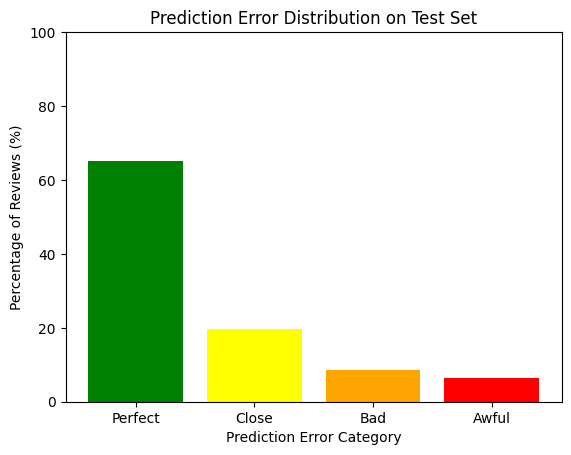

In [ ]:
import matplotlib.pyplot as plt
plt.figure()
plt.bar(category_percentages.index, category_percentages.values, color=['green', 'yellow', 'orange', 'red'])
plt.ylabel("Percentage of Reviews (%)")
plt.xlabel("Prediction Error Category")
plt.title("Prediction Error Distribution on Test Set")
plt.ylim(0, 100)
plt.show()

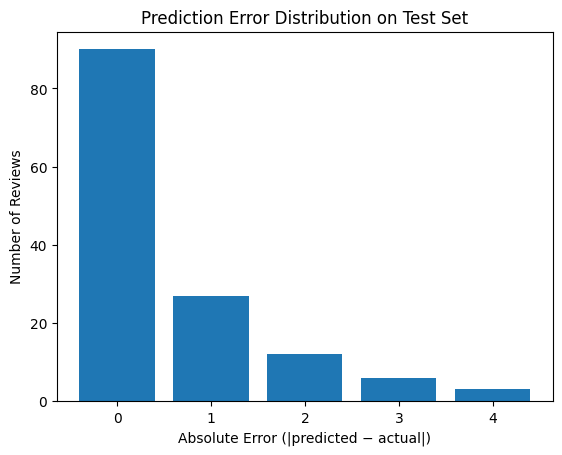

In [ ]:
import matplotlib.pyplot as plt

error_counts = df_results["error"].value_counts().sort_index()

plt.figure()
plt.bar(error_counts.index, error_counts.values)
plt.xlabel("Absolute Error (|predicted − actual|)")
plt.ylabel("Number of Reviews")
plt.title("Prediction Error Distribution on Test Set")
plt.show()


In [ ]:
import random
random_idx = random.randint(0, len(dataset["test"]) - 1)
random_sample = dataset["test"][random_idx]

random_review_text = random_sample["text"]
random_actual = random_sample["rating"]
random_predicted = predict_star(random_review_text)

print("=== Random Review ===")
print("Text:", random_review_text)
print("Actual:", random_actual)
print("Predicted:", random_predicted)

=== Random Review ===
Text: TAKE JUSTIN FOR ANY CLASS! He is literally the best professor I've had at Maryland by far! He explains concepts really well and he even adds some math humor into the lectures sometimes. Even though calc 3 wasn't always easy, he explained things very well and there was never a moment in class where I felt lost. 

His exams are very fair if you pay attention in lecture, and do the suggested but optional homework problems he posts online. Definitely go to discussions because there is a quiz at least once a week in discussion. 

The quizzes in discussions are 10 points each and add up to be 100 points of the total point value of the class. There are also 3 Matlab projects throughout the semester and 1 Matlab quiz, each worth 25 points, also adding up to 100 points. We had four exams in the semester, each exam worth 100 points each. The final exam this year was written by Justin and was also fair, no surprises. 

Overall, I really enjoyed Calc 3 with Justin and I

In [ ]:
awful_samples = df_results[df_results["error"] >= 3]
awful_sample = awful_samples.sample(1).iloc[0]
idx = int(awful_sample.name)

awful_text = dataset["test"][idx]["text"]
awful_actual = awful_sample["actual"]
awful_predicted = awful_sample["predicted"]

print("\n=== Awful Review ===")
print("Text:", awful_text)
print("Actual:", awful_actual)
print("Predicted:", awful_predicted)



=== Awful Review ===
Text: This class is not as easy as people claim to be honest, especially if you have no programming or math background. Please read carefully if that's you and don't let the other reviews sway your judgement. Matlab is a programming language comparable to Java and C++, maybe even C. Heck, it was built with C. I didn't know anything about programming when taking this class, and I had to essentially teach myself C first, and dweldge into some nasty low level operating systems concepts (which is in the scope of CMSC 412, the hardest undergraduate computer science course offered here) to even comprehend how to do those complicated math equations in MATLAB.
This course sucked up so much time - I came in thinking it's an easy 1 credit, but boy oh boy oh no. It warranted weekly office hours - that is - whenever I had the time. This class, for each week's assignment, would suck up more like 10-20 hours a week and living at office hours. The fact that there is no lecture f

In [ ]:
df_results["predicted"].value_counts()
df_results["actual"].value_counts()

,count
actual,
5,83
3,15
2,14
4,13
1,13
